### Torch (2026-10-07) fails to init random state properly for multiprocessed random number generation

In [118]:
import os

import torch

if os.fork():
    print(torch.rand(10))
else:
    print(torch.rand(10))

tensor([0.5401, 0.9019, 0.0236, 0.8914, 0.7529, 0.0832, 0.7340, 0.6587, 0.9627,
        0.2960])


/tmp/ipykernel_189645/3328363967.py:5: DeprecationWarning: This process (pid=189645) is multi-threaded, use of fork() may lead to deadlocks in the child.
  if os.fork():


tensor([0.5401, 0.9019, 0.0236, 0.8914, 0.7529, 0.0832, 0.7340, 0.6587, 0.9627,
        0.2960])


### Implementing stuff from Lesson 10

In [119]:
import kagglehub

path = kagglehub.dataset_download("zalando-research/fashionmnist")

print("Path to dataset files:", path)

Path to dataset files: /home/ojke/.cache/kagglehub/datasets/zalando-research/fashionmnist/versions/4


In [120]:
from pathlib import Path

import pandas as pd

with open(Path(path) / "fashion-mnist_test.csv", "r") as test_file:
    test_data = pd.read_csv(test_file)

with open(Path(path) / "fashion-mnist_train.csv", "r") as train_file:
    train_data = pd.read_csv(train_file)

In [121]:
train_data

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59996,1,0,0,0,0,0,0,0,0,0,...,73,0,0,0,0,0,0,0,0,0
59997,8,0,0,0,0,0,0,0,0,0,...,160,162,163,135,94,0,0,0,0,0
59998,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [122]:
test_list = test_data.to_numpy().tolist()
train_list = train_data.to_numpy().tolist()

In [123]:
def split_row(row: list[int]) -> tuple[int, list[int]]:
    return row[0], row[1:]


test_split = map(split_row, test_list)
train_split = map(split_row, train_list)

In [124]:
from collections.abc import Iterable


def transpose_data(
    split: Iterable[tuple[int, list[int]]],
) -> tuple[list[int], list[list[int]]]:
    xs, ys = [], []
    for y, x in split:
        ys.append(y)
        xs.append(x)
    return ys, xs


test_y, test_x = transpose_data(test_split)
train_y, train_x = transpose_data(train_split)

In [ ]:
from itertools import batched


def to_img(img_flat: list[int], img_width: int):
    result = []
    for row in batched(img_flat, img_width):
        result.append(list(row))
    return result


test_x = [to_img(flat, 28) for flat in test_x]
train_x = [to_img(flat, 28) for flat in train_x]

(<matplotlib.image.AxesImage at 0x72d5747b6960>, 2)

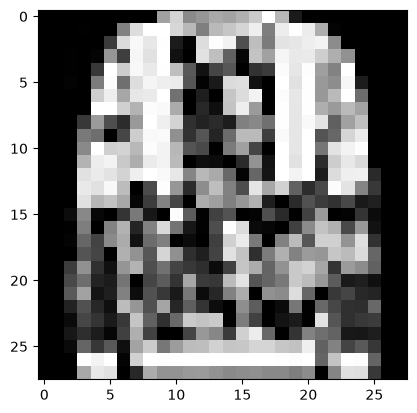

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(test_x[3], cmap="grey"), test_y[3]

(<matplotlib.image.AxesImage at 0x72d5538c60f0>, 3)

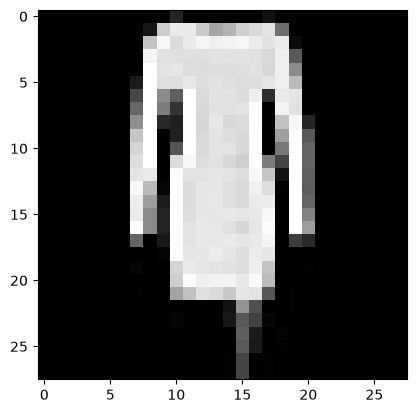

In [ ]:
plt.imshow(test_x[4], cmap="grey"), test_y[4]

In [ ]:
from functools import partial

import torch

train_x, train_y, test_x, test_y = map(
    partial(torch.tensor, dtype=torch.uint8),
    (train_x, train_y, test_x, test_y),
)

/tmp/ipykernel_189645/3526693834.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  train_x, train_y, test_x, test_y = map(


In [134]:
train_x.shape, test_x.shape

(torch.Size([60000, 28, 28]), torch.Size([10000, 28, 28]))